# Project 2 — Concrete Compressive Strength: Predicting Strength from Mix Design and Age

**Course:** Data Mining  **Dataset:** `Concrete_Data.csv` (1,030 laboratory tests; Yeh, 1998, UCI repository)

**Goal.** Predict concrete compressive strength (MPa) from the seven mixture ingredients (kg per m³) and the curing age (days); compare linear and non-linear approaches; diagnose where predictions fail; and discuss whether the cement–strength association is causal.

| Section | Assignment task |
|---|---|
| 1. Setup | – |
| 2. Data understanding and short data report | Task 1 |
| 3. Data preparation, with justification | Task 1 |
| 4. Mean-prediction baseline | Task 1 |
| 5. Linear vs non-linear models | Task 2 |
| 6. Residual analysis: where are predictions weakest? | Task 2 |
| 7. Does the cement–strength association prove what happens if we change the mix? | Task 3 |
| 8. Conclusions | – |

All randomness is seeded (`RANDOM_STATE = 42`); the notebook runs top to bottom in about a minute.

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

from sklearn.model_selection import GroupKFold, GroupShuffleSplit, KFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import partial_dependence
from sklearn.base import clone

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
     "magenta": "#e87ba4", "violet": "#6250d6", "grey": "#8a8984", "red": "#e34948"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.labelsize": 10, "legend.frameon": False, "lines.linewidth": 2,
})
DATA_PATH = Path("data") / "Concrete_Data.csv"

## 2. Data understanding (exploratory analysis)

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Original column names:", list(raw.columns), sep="\n  ")
COLS = ["cement", "slag", "fly_ash", "water", "superplasticizer", "coarse_agg", "fine_agg", "age", "strength"]
raw.columns = COLS
INGREDIENTS = COLS[:7]
print("\nShape:", raw.shape)
raw.head()

Original column names:
  ['Cement (kg in a m^3 mixture)', 'Blast Furnace Slag (kg in a m^3 mixture)', 'Fly Ash (kg in a m^3 mixture)', 'Water (kg in a m^3 mixture)', 'Superplasticizer (kg in a m^3 mixture)', 'Coarse Aggregate (kg in a m^3 mixture)', 'Fine Aggregate (kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength (MPa, megapascals) ']

Shape: (1030, 9)


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [3]:
summary = raw.describe().T
summary["n_missing"] = raw.isna().sum()
summary["n_zero"] = (raw == 0).sum()
summary["skew"] = raw.skew()
print("Exact duplicate rows:", raw.duplicated().sum())
summary.round(2)

Exact duplicate rows: 25


,count,mean,std,min,25%,50%,75%,max,n_missing,n_zero,skew
cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0,0,0,0.51
slag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4,0,466,0.80
fly_ash,1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1,0,566,0.54
water,1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0,0,0,0.07
superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2,0,379,0.91
coarse_agg,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0,0,0,-0.04
fine_agg,1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6,0,0,-0.25
age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0,0,0,3.27
strength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6,0,0,0.42


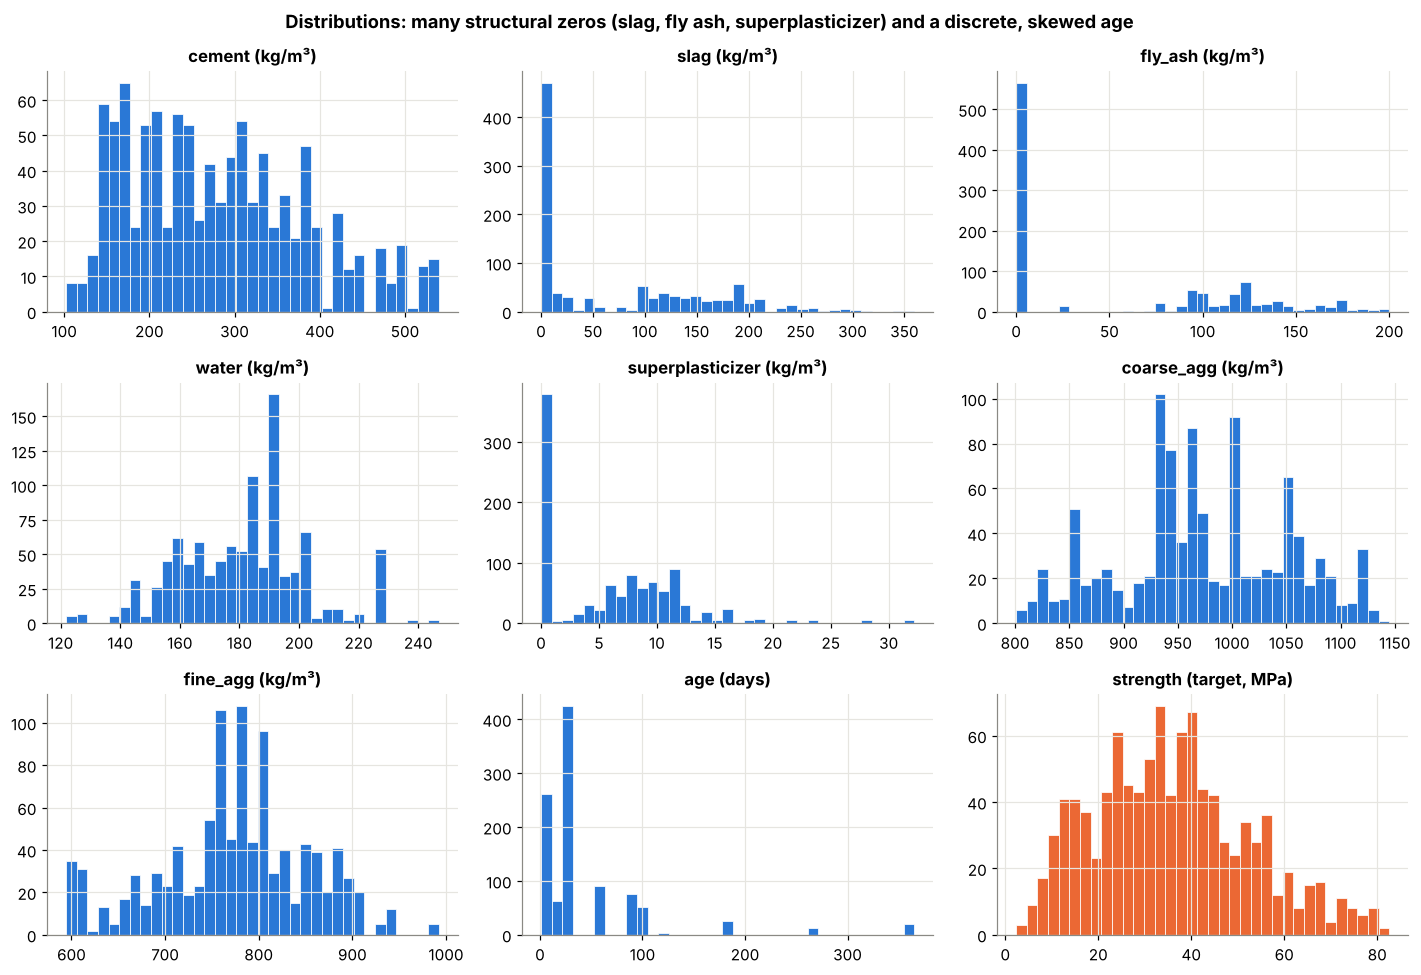

Distinct ages (days): [np.int64(1), np.int64(3), np.int64(7), np.int64(14), np.int64(28), np.int64(56), np.int64(90), np.int64(91), np.int64(100), np.int64(120), np.int64(180), np.int64(270), np.int64(360), np.int64(365)]
age
1        2
3      134
7      126
14      62
28     425
56      91
90      54
91      22
100     52
120      3
180     26
270     13
360      6
365     14


In [4]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, col in zip(axes.ravel(), COLS):
    ax.hist(raw[col], bins=35, color=C["blue"] if col != "strength" else C["orange"], edgecolor="white", linewidth=0.5)
    ax.set_title(col + (" (target, MPa)" if col == "strength" else " (days)" if col == "age" else " (kg/m³)"))
fig.suptitle("Distributions: many structural zeros (slag, fly ash, superplasticizer) and a discrete, skewed age",
             fontweight="bold")
plt.tight_layout(); plt.show()
print("Distinct ages (days):", sorted(raw.age.unique()))
print(raw.age.value_counts().sort_index().to_string())

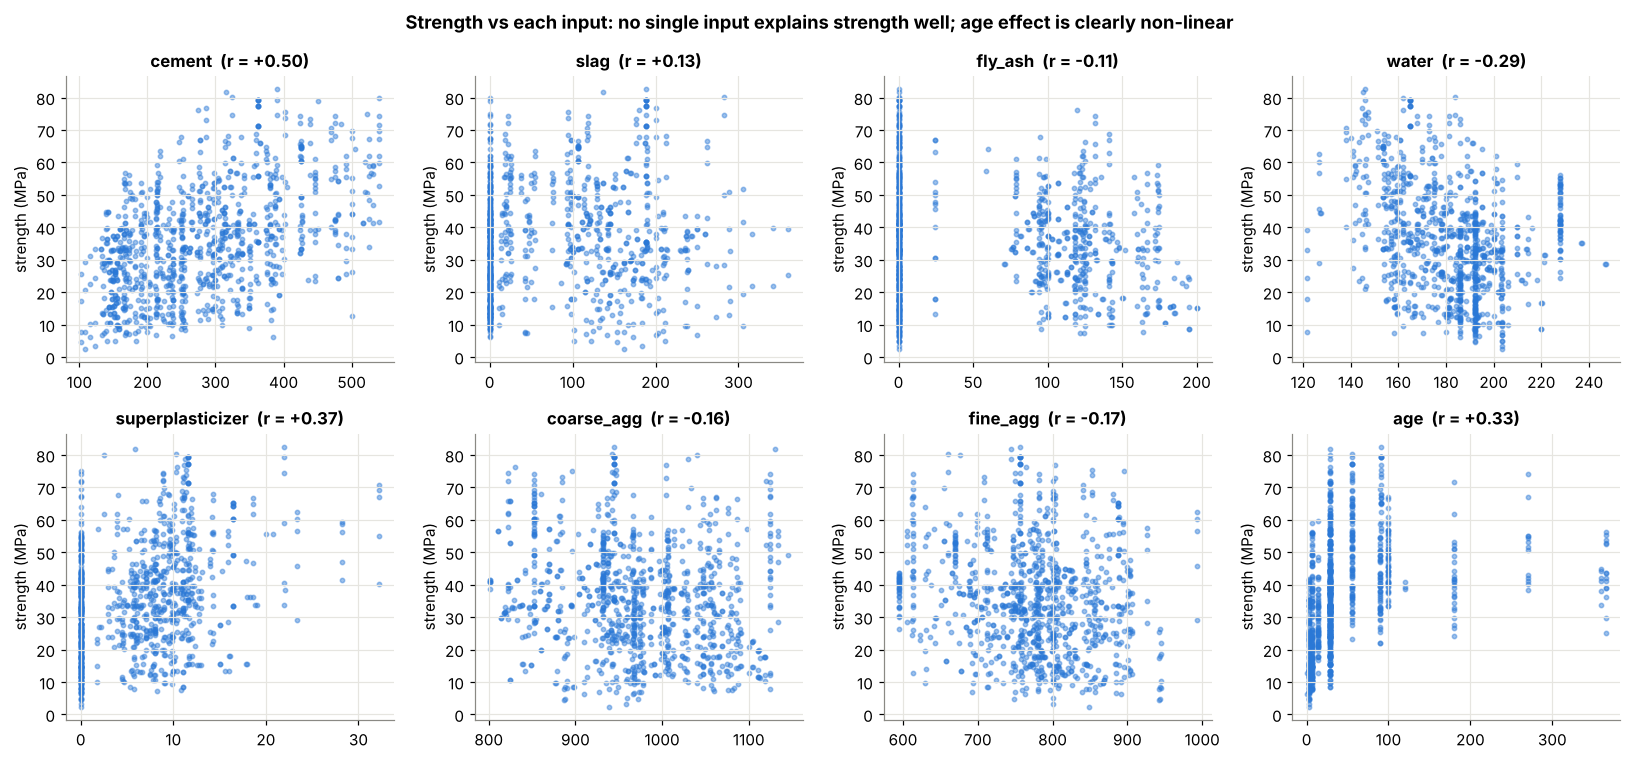

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, col in zip(axes.ravel(), COLS[:8]):
    ax.scatter(raw[col], raw["strength"], s=8, alpha=0.45, color=C["blue"])
    r = raw[[col, "strength"]].corr().iloc[0, 1]
    ax.set_title(f"{col}  (r = {r:+.2f})"); ax.set_ylabel("strength (MPa)")
fig.suptitle("Strength vs each input: no single input explains strength well; age effect is clearly non-linear",
             fontweight="bold")
plt.tight_layout(); plt.show()

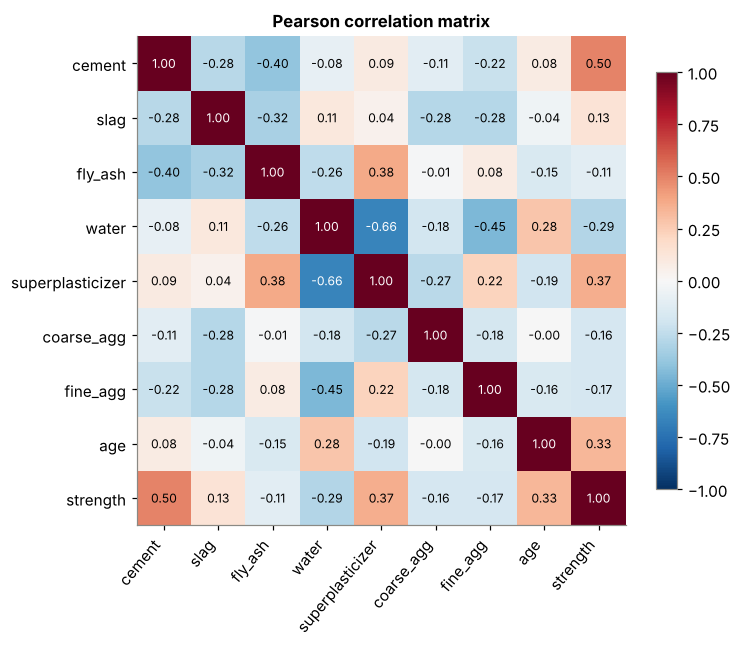

In [6]:
corr = raw.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(9)); ax.set_xticklabels(COLS, rotation=50, ha="right")
ax.set_yticks(range(9)); ax.set_yticklabels(COLS)
for i in range(9):
    for j in range(9):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Pearson correlation matrix")
plt.tight_layout(); plt.show()

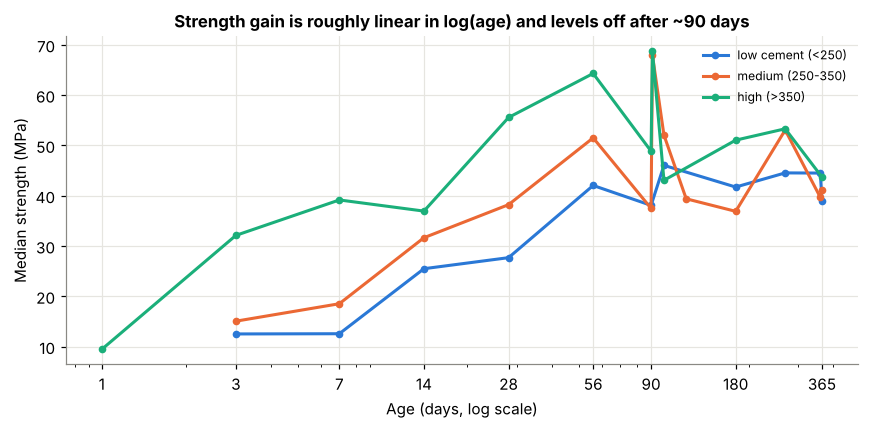

In [7]:
# Strength grows with age along a concave curve, at a level set by the mix (shown here by cement content)
d = raw.copy()
d["cement band"] = pd.cut(d.cement, [0, 250, 350, 600], labels=["low cement (<250)", "medium (250-350)", "high (>350)"])
g = d.groupby(["cement band", "age"], observed=True)["strength"].median().reset_index()
fig, ax = plt.subplots(figsize=(8, 4))
for band, colr in zip(g["cement band"].cat.categories, [C["blue"], C["orange"], C["aqua"]]):
    s = g[g["cement band"] == band]
    ax.plot(s.age, s.strength, marker="o", ms=4, color=colr, label=band)
ax.set_xscale("log"); ax.set_xticks([1, 3, 7, 14, 28, 56, 90, 180, 365]); ax.set_xticklabels([1, 3, 7, 14, 28, 56, 90, 180, 365])
ax.set_xlabel("Age (days, log scale)"); ax.set_ylabel("Median strength (MPa)")
ax.set_title("Strength gain is roughly linear in log(age) and levels off after ~90 days")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

In [8]:
# How many distinct mixtures are there? The same mix is often tested at several ages.
mix_id = raw.groupby(INGREDIENTS, sort=False).ngroup()
per_mix = raw.assign(mix=mix_id).drop_duplicates().groupby("mix").size()
print("Distinct mixtures:", mix_id.nunique(), " | rows:", len(raw))
print("Rows per mixture (after removing exact duplicates):")
print(per_mix.value_counts().sort_index().rename("number of mixtures").to_string())

# Total mass per m3 is nearly constant -> ingredients are compositional (substitutes)
total = raw[INGREDIENTS].sum(axis=1)
print(f"\nTotal ingredient mass per m³: mean {total.mean():.0f} kg, sd {total.std():.0f} kg (CV {total.std()/total.mean():.1%})")

Distinct mixtures: 428  | rows: 1030
Rows per mixture (after removing exact duplicates):
1    246
2     42
3      7
4     38
5     77
6     12
7      3
8      3

Total ingredient mass per m³: mean 2344 kg, sd 65 kg (CV 2.8%)


### 2.1 Short data report

* **Size and quality.** 1,030 rows, 8 numeric inputs and a numeric target; **no missing values**. There are **25 exact duplicate rows** (identical mix, age *and* strength). Units are consistent (kg/m³, days, MPa).
* **Structural zeros.** `slag` (466 zeros), `fly_ash` (566) and `superplasticizer` (379) are often 0. These are not missing values: the ingredient was simply not used. They are kept as genuine zeros.
* **Target.** Strength ranges from 2.3 to 82.6 MPa (mean 35.8, sd 16.7). The distribution is roughly symmetric with a mild right tail, so no transformation of the target is needed.
* **Age** takes only 14 distinct values (1 – 365 days) and is strongly right-skewed: 42 % of tests are at 28 days, and few tests are older than 100 days. Strength rises steeply over the first 28 days and then levels off, a **concave, non-linear** pattern that is close to linear in log(age).
* **Associations.** `cement` has the strongest linear correlation with strength (r = +0.50), followed by `superplasticizer` (+0.37), `age` (+0.33) and `water` (−0.29). No single variable explains much, which indicates that **interactions and non-linear effects** matter, e.g. the water-to-binder ratio (Abrams' law).
* **Mixtures are repeated.** There are only **428 distinct mixtures**. Most are tested at several ages, and some are replicated at the same age. This matters for validation: a random split lets the model see the *same mix* at other ages during training, so performance on genuinely *new* mixes would be over-estimated.
* **Compositional constraint.** The ingredients add up to an almost constant ≈ 2,340 kg/m³ (CV ≈ 3 %). Increasing one ingredient implies reducing others, which is why `cement` is negatively correlated with `slag` (−0.28) and `fly_ash` (−0.40). This becomes central in Task 3.
* **Outliers.** The extreme values (e.g. cement 540 kg/m³, superplasticizer 32 kg/m³, age 365 d) are physically plausible mix designs, not errors, so they are kept.

## 3. Data preparation (with justification)

| Step | Action | Justification |
|---|---|---|
| 1 | Rename columns to short names | Readability; the original names contain units and spaces. |
| 2 | **Remove the 25 exact duplicate rows** | They carry no new information and, if split across train and test, would leak exact answers. |
| 3 | Keep zeros and plausible extreme values | They are real mix designs (ingredient not used / high-performance mixes), not errors. |
| 4 | Create a **mixture ID** and split train/test **by mixture** (`GroupShuffleSplit`, 80/20); cross-validate with `GroupKFold` | The realistic question is “how strong will a *new* mix be?”. Grouping prevents the same mix (at a different age) appearing in both training and evaluation. Section 5.4 quantifies the optimism of a naïve random split. |
| 5 | Domain-informed features for the linear models: `log_age`, `water_binder` = water / (cement + slag + fly ash), `binder` total | Linear regression cannot learn curvature or ratios by itself. These features encode well-known concrete science (logarithmic strength gain; Abrams' water–binder law) while keeping the model linear in its parameters. |
| 6 | Standardise inputs inside a `Pipeline` (linear models only) | Needed for regularised/polynomial models; fitting the scaler inside CV avoids leakage. Tree ensembles are scale-invariant and use the raw 8 inputs. |

In [9]:
df = raw.drop_duplicates().reset_index(drop=True)
df["mix_id"] = df.groupby(INGREDIENTS, sort=False).ngroup()
print("After removing duplicates:", df.shape, "| distinct mixtures:", df.mix_id.nunique())

def add_domain_features(X):
    X = X.copy()
    X["binder"] = X["cement"] + X["slag"] + X["fly_ash"]
    X["water_binder"] = X["water"] / X["binder"]
    X["log_age"] = np.log(X["age"])
    return X

RAW_FEATS = INGREDIENTS + ["age"]
X_all, y_all, groups_all = df[RAW_FEATS], df["strength"], df["mix_id"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
tr_idx, te_idx = next(gss.split(X_all, y_all, groups_all))
X_train, X_test = X_all.iloc[tr_idx], X_all.iloc[te_idx]
y_train, y_test = y_all.iloc[tr_idx], y_all.iloc[te_idx]
g_train = groups_all.iloc[tr_idx]
print(f"Train: {len(X_train)} rows / {g_train.nunique()} mixes | Test: {len(X_test)} rows / {groups_all.iloc[te_idx].nunique()} mixes")
print("Mixtures shared between train and test:", len(set(g_train) & set(groups_all.iloc[te_idx])))
print(f"Mean strength train {y_train.mean():.1f} MPa vs test {y_test.mean():.1f} MPa")

cv = GroupKFold(n_splits=5)

After removing duplicates: (1005, 10) | distinct mixtures: 428
Train: 799 rows / 342 mixes | Test: 206 rows / 86 mixes
Mixtures shared between train and test: 0
Mean strength train 35.0 MPa vs test 36.4 MPa


In [10]:
# Irreducible noise: mixes tested more than once at the SAME age (replicates) give a lower bound on achievable error
# Replicates: the same mix tested more than once at the SAME age (after removing exact duplicates)
rep = df.groupby(INGREDIENTS + ["age"])["strength"].agg(["count", "std", "min", "max"]).query("count > 1")
print(f"Replicate groups: {len(rep)} | median within-group SD = {rep['std'].median():.2f} MPa")
rep.round(2)

Replicate groups: 9 | median within-group SD = 1.39 MPa


count    std    min    max
cement slag  fly_ash water superplasticizer coarse_agg fine_agg age                            
359.0  19.0  141.0   154.0 10.91            942.0      801.0    3        2   1.04  23.64  25.12
                                                                7        2   2.02  35.75  38.61
                                                                28       2   2.43  59.49  62.94
                                                                56       2   1.39  66.78  68.75
362.6  189.0 0.0     164.9 11.60            944.7      755.8    7        2  23.33  22.90  55.90
446.0  24.0  79.0    162.0 11.64            967.0      712.0    3        2   1.18  23.35  25.02
                                                                7        2   0.91  38.02  39.30
                                                                28       2   4.67  44.42  51.02
                                                                56       2   0.63  55.25  56.14

Most replicate pairs agree within about 1 – 2 MPa, which is the typical test-to-test scatter. One mix (cement 362.6 kg/m³, 7 days) has two records that differ by **≈ 33 MPa**. That is almost certainly a recording or testing error. It is kept, because removing it on the basis of the target would be arbitrary with so few replicates, but it is flagged: it will appear among the largest residuals in Section 6.

## 4. Mean-prediction baseline

`DummyRegressor(strategy="mean")` predicts the training-set mean strength for every sample. By construction its R² is ≈ 0, and its RMSE is about the standard deviation of strength. Every model must beat these values.

In [11]:
def reg_metrics(y_true, y_pred):
    return {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}

baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
base_test = reg_metrics(y_test, baseline.predict(X_test))
base_cv = cross_validate(DummyRegressor(), X_train, y_train, groups=g_train, cv=cv,
                         scoring=("neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"))
print(f"Baseline predicts {baseline.constant_[0][0]:.2f} MPa for every mix")
print("Test  :", {k: round(v, 3) for k, v in base_test.items()})
print("CV    : RMSE {:.2f}, MAE {:.2f}, R2 {:.3f}".format(-base_cv["test_neg_root_mean_squared_error"].mean(),
      -base_cv["test_neg_mean_absolute_error"].mean(), base_cv["test_r2"].mean()))

Baseline predicts 34.97 MPa for every mix
Test  : {'RMSE': np.float64(18.016), 'MAE': 14.476, 'R2': -0.006}
CV    : RMSE 15.79, MAE 12.80, R2 -0.002


The baseline is wrong by about **16 MPa (grouped CV) to 18 MPa (test)** in RMSE, i.e. roughly half of the mean strength. R² is ≈ 0, slightly negative out-of-sample, as expected when a training mean is applied to new data. These are the reference values every model must beat.

## 5. Linear vs non-linear models (Task 2)

We compare a ladder of increasingly flexible models. All are fitted only on the training mixes and evaluated with **5-fold GroupKFold CV** (by mixture) and then once on the held-out test mixes.

| # | Model | Family | Why include it |
|---|---|---|---|
| L1 | Linear regression, 8 raw inputs | Linear | The textbook linear benchmark. |
| L2 | Linear regression + domain features (`log_age`, `water_binder`, `binder`) | Linear in parameters | Tests how far a linear model gets with engineering knowledge. |
| L3 | Polynomial (degree 2) Ridge on L2 features | Linear in parameters, non-linear in inputs | Adds all pairwise interactions and squares; ridge penalty tuned by CV. |
| N1 | Random Forest | Non-linear (bagged trees) | Learns interactions/thresholds automatically; robust. |
| N2 | Gradient Boosting | Non-linear (boosted trees) | Typically the most accurate on small tabular data; tuned by grouped CV. |

In [12]:
domain = FunctionTransformer(add_domain_features)

models = {
    "L1 Linear (raw)": Pipeline([("scale", StandardScaler()), ("lr", LinearRegression())]),
    "L2 Linear + domain features": Pipeline([("fe", domain), ("scale", StandardScaler()), ("lr", LinearRegression())]),
    "L3 Polynomial-2 Ridge": Pipeline([("fe", domain), ("scale", StandardScaler()),
                                       ("poly", PolynomialFeatures(2, include_bias=False)), ("scale2", StandardScaler()),
                                       ("ridge", RidgeCV(alphas=np.logspace(-3, 3, 30)))]),
    "N1 Random Forest": RandomForestRegressor(n_estimators=500, min_samples_leaf=1, max_features=0.6,
                                              n_jobs=-1, random_state=RANDOM_STATE),
}

# Tune gradient boosting with grouped CV on the training mixes only
gb_grid = GridSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE, subsample=0.8),
    {"n_estimators": [300, 600, 1000], "learning_rate": [0.03, 0.1], "max_depth": [3, 4, 5]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
gb_grid.fit(X_train, y_train, groups=g_train)
print("Best GB params:", gb_grid.best_params_, "| grouped-CV RMSE:", round(-gb_grid.best_score_, 2))
models["N2 Gradient Boosting"] = gb_grid.best_estimator_
FAMILY = {n: ("Linear" if n.startswith("L") else "Non-linear") for n in models}
MODEL_COLORS = dict(zip(models, [C["blue"], C["violet"], C["magenta"], C["orange"], C["aqua"]]))

Best GB params: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 1000} | grouped-CV RMSE: 5.35


In [13]:
scoring = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}
cv_rows, fold_rmse = [], {}
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, groups=g_train, cv=cv, scoring=scoring, n_jobs=-1)
    fold_rmse[name] = -r["test_RMSE"]
    cv_rows.append({"Model": name, "Family": FAMILY[name],
                    "CV RMSE": -r["test_RMSE"].mean(), "RMSE sd": r["test_RMSE"].std(),
                    "CV MAE": -r["test_MAE"].mean(), "CV R2": r["test_R2"].mean(), "R2 sd": r["test_R2"].std()})
cv_rows.insert(0, {"Model": "Baseline (mean)", "Family": "–",
                   "CV RMSE": -base_cv["test_neg_root_mean_squared_error"].mean(),
                   "RMSE sd": base_cv["test_neg_root_mean_squared_error"].std(),
                   "CV MAE": -base_cv["test_neg_mean_absolute_error"].mean(),
                   "CV R2": base_cv["test_r2"].mean(), "R2 sd": base_cv["test_r2"].std()})
cv_table = pd.DataFrame(cv_rows).set_index("Model")
cv_table.round(3)

,Family,CV RMSE,RMSE sd,CV MAE,CV R2,R2 sd
Model,,,,,,
Baseline (mean),–,15.790,0.696,12.801,-0.002,0.002
L1 Linear (raw),Linear,10.334,0.716,8.230,0.571,0.028
L2 Linear + domain features,Linear,7.013,0.434,5.495,0.802,0.016
L3 Polynomial-2 Ridge,Linear,6.136,0.888,4.676,0.847,0.035
N1 Random Forest,Non-linear,5.963,0.805,4.476,0.857,0.029
N2 Gradient Boosting,Non-linear,5.347,0.639,3.948,0.884,0.022


In [14]:
fitted = {n: clone(m).fit(X_train, y_train) for n, m in models.items()}
test_pred = {n: m.predict(X_test) for n, m in fitted.items()}
test_table = pd.DataFrame({n: reg_metrics(y_test, p) for n, p in test_pred.items()}).T
test_table.loc["Baseline (mean)"] = base_test
test_table.insert(0, "Family", [FAMILY.get(n, "–") for n in test_table.index])

# Bootstrap 95% CI for test RMSE
rng = np.random.default_rng(RANDOM_STATE); yt = y_test.to_numpy()
boot_idx = [rng.integers(0, len(yt), len(yt)) for _ in range(1000)]
for n, p in test_pred.items():
    b = [np.sqrt(mean_squared_error(yt[i], p[i])) for i in boot_idx]
    test_table.loc[n, "RMSE 95% CI"] = f"[{np.percentile(b, 2.5):.2f}, {np.percentile(b, 97.5):.2f}]"
test_table.sort_values("RMSE").round(3)

,Family,RMSE,MAE,R2,RMSE 95% CI
N1 Random Forest,Non-linear,6.545,4.587,0.867,"[5.57, 7.51]"
N2 Gradient Boosting,Non-linear,6.552,4.648,0.867,"[5.71, 7.37]"
L3 Polynomial-2 Ridge,Linear,7.151,4.925,0.842,"[5.86, 8.41]"
L2 Linear + domain features,Linear,7.488,5.654,0.826,"[6.52, 8.45]"
L1 Linear (raw),Linear,10.792,8.678,0.639,"[9.69, 11.87]"
Baseline (mean),–,18.016,14.476,-0.006,NaN


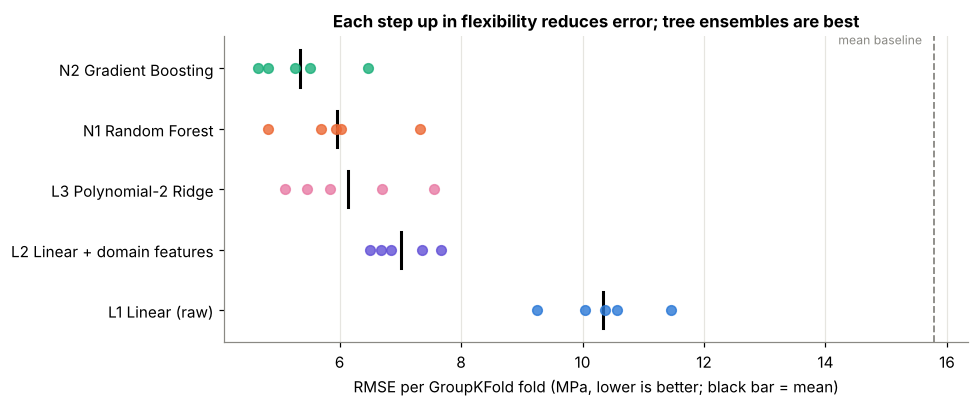

Best linear: L3 Polynomial-2 Ridge | best non-linear: N2 Gradient Boosting
Paired fold difference in RMSE (linear − non-linear): mean 0.79 MPa, non-linear better in 5/5 folds; paired t-test p = 0.1135


In [15]:
fig, ax = plt.subplots(figsize=(9, 3.8))
names = list(models)
for i, n in enumerate(names):
    ax.scatter(fold_rmse[n], [i] * 5, color=MODEL_COLORS[n], s=40, alpha=0.8, zorder=3)
    ax.plot([fold_rmse[n].mean()] * 2, [i - 0.3, i + 0.3], color="black", lw=2)
ax.axvline(cv_table.loc["Baseline (mean)", "CV RMSE"], color=C["grey"], ls="--", lw=1.2)
ax.text(cv_table.loc["Baseline (mean)", "CV RMSE"] - 0.2, len(names) - 0.6, "mean baseline", ha="right", color=C["grey"], fontsize=8)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names); ax.grid(axis="y", visible=False)
ax.set_xlabel("RMSE per GroupKFold fold (MPa, lower is better; black bar = mean)")
ax.set_title("Each step up in flexibility reduces error; tree ensembles are best")
plt.tight_layout(); plt.show()

best_lin = min([n for n in models if FAMILY[n] == "Linear"], key=lambda n: cv_table.loc[n, "CV RMSE"])
best_nl = min([n for n in models if FAMILY[n] == "Non-linear"], key=lambda n: cv_table.loc[n, "CV RMSE"])
d = fold_rmse[best_lin] - fold_rmse[best_nl]
print(f"Best linear: {best_lin} | best non-linear: {best_nl}")
print(f"Paired fold difference in RMSE (linear − non-linear): mean {d.mean():.2f} MPa, "
      f"non-linear better in {np.sum(d > 0)}/5 folds; paired t-test p = {stats.ttest_rel(fold_rmse[best_lin], fold_rmse[best_nl]).pvalue:.4f}")

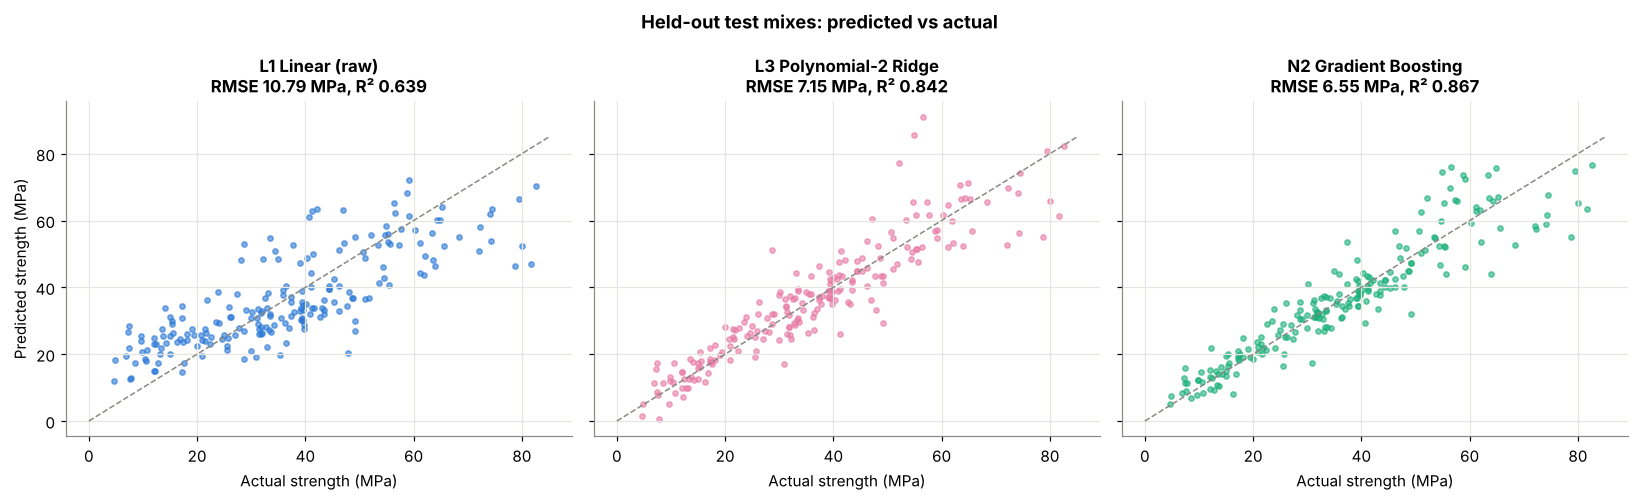

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
for ax, n in zip(axes, ["L1 Linear (raw)", best_lin, best_nl]):
    p = test_pred[n]
    ax.scatter(y_test, p, s=12, alpha=0.6, color=MODEL_COLORS[n])
    ax.plot([0, 85], [0, 85], color=C["grey"], ls="--", lw=1)
    m = reg_metrics(y_test, p)
    ax.set_title(f"{n}\nRMSE {m['RMSE']:.2f} MPa, R² {m['R2']:.3f}")
    ax.set_xlabel("Actual strength (MPa)")
axes[0].set_ylabel("Predicted strength (MPa)")
fig.suptitle("Held-out test mixes: predicted vs actual", fontweight="bold")
plt.tight_layout(); plt.show()

### 5.1 Grouped vs random cross-validation: how optimistic is a naïve split?

In [17]:
rows = []
for n in [best_lin, best_nl]:
    for label, splitter, grp in [("Random KFold", KFold(5, shuffle=True, random_state=RANDOM_STATE), None),
                                 ("GroupKFold (by mixture)", cv, g_train)]:
        r = cross_validate(models[n], X_train, y_train, groups=grp, cv=splitter,
                           scoring="neg_root_mean_squared_error", n_jobs=-1)
        rows.append({"Model": n, "CV scheme": label, "CV RMSE": -r["test_score"].mean()})
pd.DataFrame(rows).pivot(index="Model", columns="CV scheme", values="CV RMSE").round(2)

CV scheme,GroupKFold (by mixture),Random KFold
Model,,
L3 Polynomial-2 Ridge,6.14,5.67
N2 Gradient Boosting,5.35,4.24


A random split lets the model see the same mixture at other ages, so its error estimate is noticeably **optimistic**, especially for the flexible tree model, which can partly "memorise" a mixture. The grouped estimate is the honest one for the question "how strong will a **new** mix be?", and it is the one used throughout.

### 5.2 Comparison and interpretation

| Model | Family | Grouped-CV RMSE (MPa) | CV R² | Test RMSE (MPa) | Test R² |
|---|---|---|---|---|---|
| Baseline (mean) | – | 15.79 | 0.00 | 18.02 | −0.01 |
| L1 Linear (raw) | Linear | 10.33 | 0.57 | 10.79 | 0.64 |
| L2 Linear + domain features | Linear | 7.01 | 0.80 | 7.49 | 0.83 |
| L3 Polynomial-2 Ridge | Linear in parameters | 6.14 | 0.85 | 7.15 | 0.84 |
| N1 Random Forest | Non-linear | 5.96 | 0.86 | 6.55 | 0.87 |
| **N2 Gradient Boosting** | **Non-linear** | **5.35** | **0.88** | **6.55** | **0.87** |

*(Copied from the outputs above for readability, using scikit-learn 1.9. Older scikit-learn versions assign GroupKFold folds slightly differently, so CV figures can differ in the first decimal; the ranking and conclusions do not change.)*

* **Every model beats the mean baseline by a wide margin.** The best model cuts the error by about two-thirds (≈ 16 → 5.3 MPa in grouped CV).
* **Raw linear regression (L1) is clearly misspecified.** It explains only ≈ 57 – 64 % of the variance (RMSE ≈ 10 MPa), because strength is not additive in the raw ingredients: the age effect is logarithmic and the effect of water depends on the amount of binder.
* **Domain features (L2) remove a third of the linear error** (10.3 → 7.0 MPa) while staying a plain linear model. `log_age` and `water_binder` encode known physics (hydration kinetics, Abrams' law), so much of the "non-linearity" is *known structure*.
* **Polynomial ridge (L3)** adds squares and pairwise interactions and closes more of the gap (6.1 MPa).
* **Tree ensembles are best.** Gradient boosting has the lowest grouped-CV RMSE (5.35 MPa, R² 0.88) and the lowest fold-to-fold variability among the ensembles. On the held-out test mixes it ties with Random Forest (6.55 MPa, R² 0.87), with both ahead of the best linear model (7.15 MPa).
* **Strength of the evidence.** Boosting beats the best linear model on **all 5 grouped folds** (mean gain 0.79 MPa) and on the test set. With only 5 folds the paired *t*-test is not conventionally significant (p ≈ 0.11; a one-sided sign test on 5/5 folds gives p ≈ 0.03), and the test bootstrap CIs overlap. The conclusion is therefore that non-linear models are **consistently but modestly** better than a *well-engineered* linear model, and **much** better than a naïve linear model.
* **Validation design matters.** A random split makes boosting look ≈ 21 % better than it is (RMSE 4.24 vs 5.35 MPa), because it sees the same mixture at other ages (5.1).

## 6. Residual analysis: where are predictions weakest? (Task 2)

To have a residual for **every training mix** without using the test set, we use **out-of-fold predictions** from GroupKFold (each row is predicted by a model that never saw its mixture). We compare the best linear and the best non-linear model. Residual = actual − predicted (positive = model under-predicts).

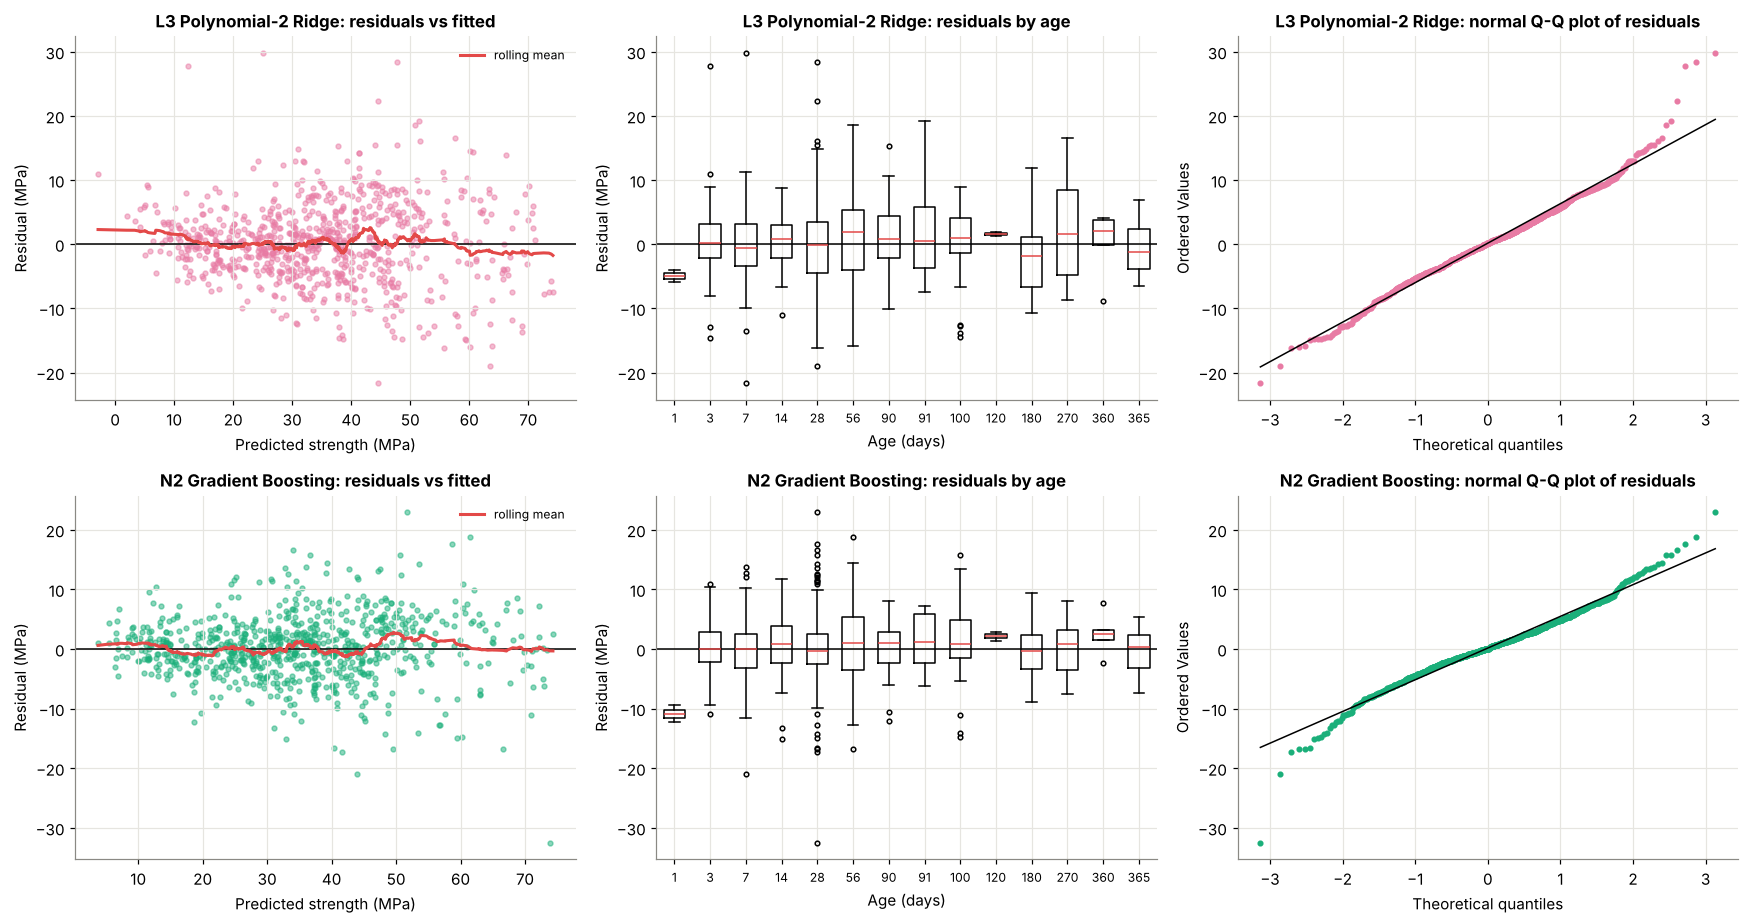

In [18]:
oof = {n: cross_val_predict(models[n], X_train, y_train, groups=g_train, cv=cv, n_jobs=-1) for n in [best_lin, best_nl]}
res = X_train.copy()
res["strength"] = y_train.values
for n in oof:
    res[f"pred_{n}"] = oof[n]
    res[f"resid_{n}"] = y_train.values - oof[n]

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for row, n in enumerate([best_lin, best_nl]):
    r, p = res[f"resid_{n}"], res[f"pred_{n}"]
    ax = axes[row, 0]
    ax.scatter(p, r, s=10, alpha=0.5, color=MODEL_COLORS[n]); ax.axhline(0, color="black", lw=1)
    lo = pd.Series(r.values, index=p.values).sort_index().rolling(80, center=True, min_periods=20).mean()
    ax.plot(lo.index, lo.values, color=C["red"], lw=2, label="rolling mean")
    ax.set(xlabel="Predicted strength (MPa)", ylabel="Residual (MPa)", title=f"{n}: residuals vs fitted"); ax.legend(fontsize=8)
    ax = axes[row, 1]
    ages = sorted(res.age.unique())
    ax.boxplot([r[res.age == a] for a in ages], positions=range(len(ages)), widths=0.6, showfliers=True,
               flierprops={"markersize": 3}, medianprops={"color": C["red"]})
    ax.set_xticks(range(len(ages))); ax.set_xticklabels(ages, rotation=0, fontsize=8); ax.axhline(0, color="black", lw=1)
    ax.set(xlabel="Age (days)", ylabel="Residual (MPa)", title=f"{n}: residuals by age")
    ax = axes[row, 2]
    stats.probplot(r, dist="norm", plot=ax)
    ax.get_lines()[0].set(markerfacecolor=MODEL_COLORS[n], markeredgecolor=MODEL_COLORS[n], markersize=3)
    ax.get_lines()[1].set(color="black", lw=1)
    ax.set_title(f"{n}: normal Q-Q plot of residuals")
plt.tight_layout(); plt.show()

In [19]:
def err_by(group_col, bins=None, labels=None):
    g = res[group_col] if bins is None else pd.cut(res[group_col], bins=bins, labels=labels, include_lowest=True)
    out = {}
    for n in [best_lin, best_nl]:
        e = res[f"resid_{n}"]
        out[(n, "MAE")] = e.abs().groupby(g, observed=True).mean()
        out[(n, "bias")] = e.groupby(g, observed=True).mean()
        out[(n, "rel. MAE %")] = 100 * e.abs().groupby(g, observed=True).mean() / res["strength"].groupby(g, observed=True).mean()
    t = pd.DataFrame(out); t.insert(0, "n", g.value_counts().reindex(t.index))
    return t.round(2)

print("Error by curing age group (bias = mean residual; + means under-prediction)")
display(err_by("age", bins=[0, 3, 7, 28, 56, 365], labels=["1-3 d", "4-7 d", "8-28 d", "29-56 d", "57-365 d"]))
print("Error by PREDICTED strength band of each model (conditional bias: is the model systematically off?)")
for n in [best_lin, best_nl]:
    b = pd.cut(res[f"pred_{n}"], [-10, 20, 40, 60, 100], labels=["<20", "20-40", "40-60", ">60"])
    e = res[f"resid_{n}"]
    print(f"  {n}:")
    print(pd.DataFrame({"n": b.value_counts().sort_index(), "MAE": e.abs().groupby(b, observed=True).mean(),
                        "bias": e.groupby(b, observed=True).mean(), "resid SD": e.groupby(b, observed=True).std()}).round(2).to_string())
print("\nError by ACTUAL strength band (note: binning on the actual value builds in some regression-to-the-mean)")
display(err_by("strength", bins=[0, 20, 40, 60, 90], labels=["<20 MPa", "20-40", "40-60", ">60 MPa"]))
print("Rows in the training data at each age:", res.age.value_counts().sort_index().to_dict())
res["mix_type"] = np.select(
    [(res.slag == 0) & (res.fly_ash == 0), (res.slag > 0) & (res.fly_ash > 0)],
    ["cement only (no slag/fly ash)", "both slag and fly ash"], default="one supplementary material")
print("Error by binder composition")
display(err_by("mix_type"))

Error by curing age group (bias = mean residual; + means under-prediction)


n L3 Polynomial-2 Ridge                  N2 Gradient Boosting                 
                                MAE  bias rel. MAE %                  MAE  bias rel. MAE %
age                                                                                       
1-3 d     102                  3.61  0.43      19.83                 3.53 -0.15      19.43
4-7 d      95                  4.34 -0.05      17.48                 3.88 -0.33      15.64
8-28 d    386                  4.81 -0.03      13.70                 3.88  0.05      11.05
29-56 d    65                  6.02  1.01      11.93                 5.29  0.84      10.49
57-365 d  151                  4.68  0.28      10.26                 3.86  0.65       8.46

Error by PREDICTED strength band of each model (conditional bias: is the model systematically off?)
  L3 Polynomial-2 Ridge:
                              n   MAE  bias  resid SD
pred_L3 Polynomial-2 Ridge                           
<20                         143  3.04  0.64      4.26
20-40                       377  3.99 -0.17      5.34
40-60                       224  6.39  0.80      7.82
>60                          55  6.68 -1.33      7.98
  N2 Gradient Boosting:
                             n   MAE  bias  resid SD
pred_N2 Gradient Boosting                           
<20                        143  2.68  0.01      3.49
20-40                      373  3.66  0.16      4.86
40-60                      235  4.80  0.26      6.36
>60                         48  5.79  0.03      8.21

Error by ACTUAL strength band (note: binning on the actual value builds in some regression-to-the-mean)


n L3 Polynomial-2 Ridge                  N2 Gradient Boosting                 
                                MAE  bias rel. MAE %                  MAE  bias rel. MAE %
strength                                                                                  
<20 MPa   151                  3.33 -1.03      24.30                 2.94 -1.35      21.47
20-40     367                  3.87 -1.60      12.66                 3.57 -1.13      11.69
40-60     225                  6.14  2.54      12.73                 4.75  2.16       9.84
>60 MPa    56                  7.73  5.45      11.36                 5.96  4.57       8.76

Rows in the training data at each age: {1: 2, 3: 100, 7: 95, 14: 51, 28: 335, 56: 65, 90: 44, 91: 10, 100: 41, 120: 2, 180: 24, 270: 12, 360: 5, 365: 13}
Error by binder composition


n L3 Polynomial-2 Ridge                  N2 Gradient Boosting                 
                                                     MAE  bias rel. MAE %                  MAE  bias rel. MAE %
mix_type                                                                                                       
both slag and fly ash          186                  6.09 -0.31      16.17                 4.90  0.38      13.01
cement only (no slag/fly ash)  192                  3.56  0.08      11.25                 3.26 -0.39      10.30
one supplementary material     421                  4.56  0.42      12.92                 3.84  0.31      10.89

In [20]:
# Where do the large errors of the best non-linear model concentrate?
big = res.assign(abs_err=res[f"resid_{best_nl}"].abs()).sort_values("abs_err", ascending=False)
print(f"Largest out-of-fold errors of {best_nl}:")
display(big[RAW_FEATS + ["strength", f"pred_{best_nl}", f"resid_{best_nl}"]].head(10).round(1))
q = big["abs_err"].quantile(0.9)
print(f"Top-10% errors (|resid| > {q:.1f} MPa): share at age ≤ 7 days = {(big[big.abs_err > q].age <= 7).mean():.0%} "
      f"vs {(res.age <= 7).mean():.0%} of all rows; share with strength > 60 MPa = "
      f"{(big[big.abs_err > q].strength > 60).mean():.0%} vs {(res.strength > 60).mean():.0%} of all rows")

# Test-set check that the pattern is not an artefact of CV
te = X_test.assign(err=np.abs(y_test.values - test_pred[best_nl]))
print("\nTest-set MAE of", best_nl, "by age group:")
print(te.groupby(pd.cut(te.age, [0, 3, 7, 28, 56, 365]), observed=True)["err"].agg(["count", "mean"]).round(2).to_string())

Largest out-of-fold errors of N2 Gradient Boosting:


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength,pred_N2 Gradient Boosting,resid_N2 Gradient Boosting
372,516.0,0.0,0.0,162.0,8.3,801.0,802.0,28,41.4,73.9,-32.5
119,323.7,282.8,0.0,183.8,10.3,942.7,659.9,28,74.7,51.8,22.9
105,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,22.9,43.9,-21.0
137,323.7,282.8,0.0,183.8,10.3,942.7,659.9,56,80.2,61.5,18.7
380,275.0,180.0,120.0,162.0,10.4,830.0,765.0,28,76.2,58.6,17.6
202,168.0,42.1,163.8,121.8,5.7,1058.7,780.1,28,24.2,41.6,-17.3
203,168.0,42.1,163.8,121.8,5.7,1058.7,780.1,56,32.9,49.6,-16.7
124,337.9,189.0,0.0,174.9,9.5,944.7,755.8,28,49.9,66.6,-16.7
302,252.3,0.0,98.8,146.2,14.2,987.8,889.0,28,50.6,33.9,16.7
507,436.0,0.0,0.0,218.0,0.0,838.4,719.7,28,23.8,40.4,-16.6


Top-10% errors (|resid| > 8.3 MPa): share at age ≤ 7 days = 24% vs 25% of all rows; share with strength > 60 MPa = 14% vs 7% of all rows

Test-set MAE of N2 Gradient Boosting by age group:
           count  mean
age                   
(0, 3]        29  3.33
(3, 7]        27  3.93
(7, 28]       95  4.67
(28, 56]      21  7.06
(56, 365]     34  4.78


### 6.1 Residual findings: where predictions are weakest

**Shared pattern (both models): error grows with strength (heteroscedasticity).** In the *predicted-strength* table, the residual SD of gradient boosting rises from ≈ 3.5 MPa for mixes predicted below 20 MPa to ≈ 8.2 MPa above 60 MPa (ridge: 4.3 → 8.0). The fan shape in the *residuals vs fitted* plots shows the same thing. A single "± RMSE" error bar is therefore misleading. Predictions for **high-strength concrete are the least precise in absolute terms**, and these mixes are also over-represented among the largest errors: 14 % of the top-10 % errors vs 7 % of all rows.

**Where each model is weakest:**

1. **Best linear model (L3 polynomial ridge).**
   * *Systematic bias at the extremes.* Its rolling-mean residual is positive at low fitted values and negative above ≈ 60 MPa: it **over-predicts the strongest mixes** (bias ≈ −1.3 MPa for predictions > 60). A global polynomial cannot bend locally to follow saturation.
   * *Heavier tails.* The Q-Q plot shows several residuals of 20 – 30 MPa, well beyond a normal distribution.
   * Higher error than boosting in every group, most of all in **blended slag + fly-ash mixes** (MAE 6.1 vs 3.6 MPa for cement-only mixes).
2. **Best non-linear model (gradient boosting).**
   * *Little conditional bias* (mean residual ≈ 0 in every predicted-strength band), but the **largest spread at high strength**, as described above.
   * *Ages with few training examples.* The 56-day group has the highest absolute error out-of-fold (MAE ≈ 5.3 MPa) and on the test set (≈ 7.1 MPa). **1-day** tests (only 2 training rows) are over-predicted by ≈ 11 MPa (see the age box-plot), so the model is **extrapolating** at that edge. Ages 120 – 365 days are also thinly sampled.
   * *Early age in relative terms.* At 1 – 7 days the absolute error is small (≈ 3.5 MPa), but relative to the low strength it is **≈ 16 – 19 % vs ≈ 8 – 11 % at later ages**. Early strength depends on cement chemistry and curing temperature, which are not recorded.
   * *Blended binders.* Mixes with **both slag and fly ash** have MAE 4.9 MPa (13 %) vs 3.3 MPa (10 %) for cement-only mixes. Their strength development is more varied and harder to learn from 186 examples.
3. **Data-quality limits.** Several of the largest residuals are probably not model failures. One is the 7-day replicate pair that differs by 33 MPa (Section 3). Another is a 516 kg/m³ cement, low-water mix recorded at only 41 MPa at 28 days, where the model (learning from other high-cement, low-water mixes) expects ≈ 74 MPa. No model can, or should, fit such records.

**Evidence:** residual plots (fitted, age, Q-Q), the MAE / bias / relative-error tables by age, predicted and actual strength band and binder type, the ten largest residuals, and the test-set MAE by age group, which reproduces the out-of-fold pattern on unseen mixes. *Note:* the table by **actual** strength shows under-prediction of strong mixes for both models, but part of that is the regression-to-the-mean effect of binning on the observed value. The **predicted**-band table is the unbiased check.

## 7. Does a predictive association between cement and strength prove what will happen if we change the mix? (Task 3)

**Short answer: No.** A predictive association, even a very accurate one, does not on its own tell us the effect of *intervening* on the mix. The evidence below shows why for this dataset.

### 7.1 The 'effect' of cement depends on what else is in the model

In [21]:
Xd = add_domain_features(X_train)
specs = {
    "Cement only": ["cement"],
    "Cement + age": ["cement", "age"],
    "All 7 ingredients + age": RAW_FEATS,
    "All + log_age + water_binder": RAW_FEATS + ["log_age", "water_binder"],
}
rows = []
for label, cols in specs.items():
    lr = LinearRegression().fit(Xd[cols], y_train)
    rows.append({"Model specification": label,
                 "Cement coefficient (MPa per +100 kg/m³)": 100 * lr.coef_[cols.index("cement")],
                 "R² (train)": lr.score(Xd[cols], y_train)})
coef_tab = pd.DataFrame(rows).set_index("Model specification").round(3)
coef_tab

,Cement coefficient (MPa per +100 kg/m³),R² (train)
Model specification,,
Cement only,6.963,0.204
Cement + age,6.528,0.290
All 7 ingredients + age,11.517,0.589
All + log_age + water_binder,9.326,0.819


In [22]:
print("Correlation of cement with the other ingredients (training data):")
print(X_train[INGREDIENTS].corr()["cement"].drop("cement").round(2).to_string())

Correlation of cement with the other ingredients (training data):
slag               -0.33
fly_ash            -0.37
water               0.00
superplasticizer   -0.03
coarse_agg         -0.00
fine_agg           -0.30


The estimated "effect" of +100 kg/m³ of cement changes substantially depending on which other variables are adjusted for. That is the signature of **confounding / substitution**: cement content moves together with slag, fly ash, water and aggregate in how the mixes were designed. A single coefficient is therefore not a stable property of cement.

### 7.2 What the non-linear model says: partial dependence and individual (ICE) curves

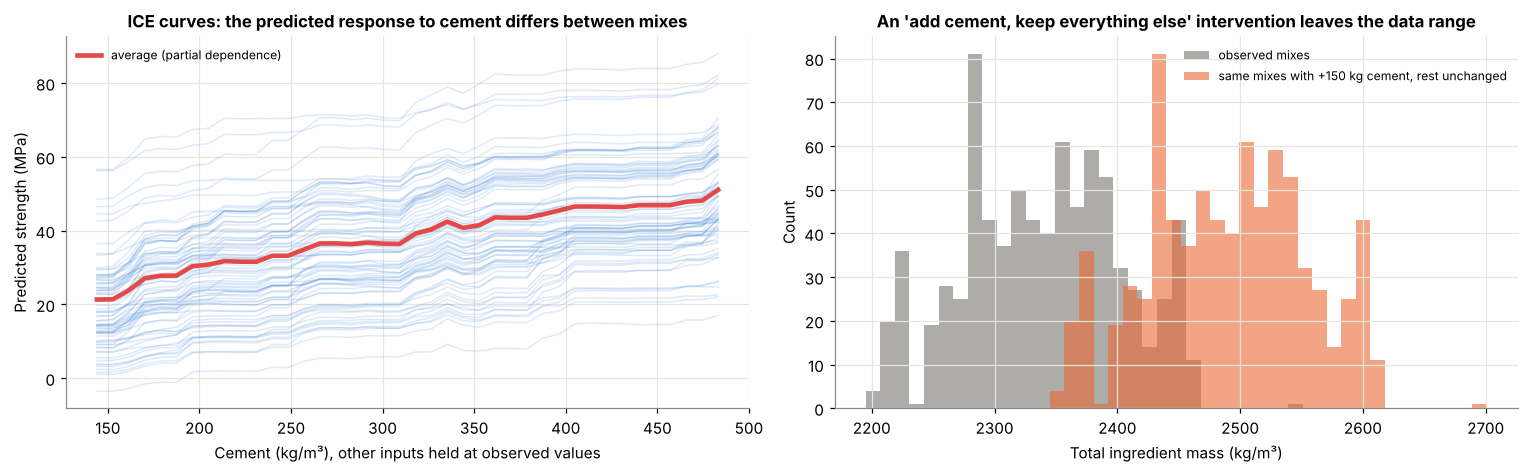

Per-mix ICE slope (MPa per +100 kg cement across the grid): median 8.9, 5th–95th percentile [6.1, 11.8]
Share of observed totals exceeded after +150 kg: 19% of mixes would be heavier than any observed mix


In [23]:
gb = fitted[best_nl]
pdp = partial_dependence(gb, X_train, features=["cement"], kind="both", grid_resolution=40)
grid = pdp["grid_values"][0] if "grid_values" in pdp else pdp["values"][0]
ice = pdp["individual"][0]; avg = pdp["average"][0]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]
sample = np.random.default_rng(RANDOM_STATE).choice(ice.shape[0], 80, replace=False)
for i in sample:
    ax.plot(grid, ice[i], color=C["blue"], alpha=0.15, lw=1)
ax.plot(grid, avg, color=C["red"], lw=3, label="average (partial dependence)")
ax.set(xlabel="Cement (kg/m³), other inputs held at observed values", ylabel="Predicted strength (MPa)",
       title="ICE curves: the predicted response to cement differs between mixes")
ax.legend(fontsize=8)

# Hold-other-inputs-fixed changes create mixes OUTSIDE the data: total mass drifts away from the observed range
ax = axes[1]
tot = X_train[INGREDIENTS].sum(axis=1)
ax.hist(tot, bins=30, color=C["grey"], alpha=0.7, label="observed mixes")
ax.hist(tot + 150, bins=30, color=C["orange"], alpha=0.6, label="same mixes with +150 kg cement, rest unchanged")
ax.set(xlabel="Total ingredient mass (kg/m³)", ylabel="Count",
       title="An 'add cement, keep everything else' intervention leaves the data range")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

slopes = (ice[:, -1] - ice[:, 0]) / (grid[-1] - grid[0]) * 100
print(f"Per-mix ICE slope (MPa per +100 kg cement across the grid): median {np.median(slopes):.1f}, "
      f"5th–95th percentile [{np.percentile(slopes, 5):.1f}, {np.percentile(slopes, 95):.1f}]")
print(f"Share of observed totals exceeded after +150 kg: {(tot + 150 > tot.max()).mean():.0%} of mixes would be heavier than any observed mix")

### 7.3 A within-stratum check (holding water–binder ratio roughly constant)

In [24]:
strat = Xd.assign(strength=y_train.values, wb_band=pd.qcut(Xd["water_binder"], 4),
                  age_28=(Xd.age == 28))
s28 = strat[strat.age_28]
rows = []
for band, g in s28.groupby("wb_band", observed=True):
    if len(g) > 10:
        r = np.corrcoef(g.cement, g.strength)[0, 1]
        slope = np.polyfit(g.cement, g.strength, 1)[0] * 100
        rows.append({"water/binder band": str(band), "n (28-day tests)": len(g),
                     "corr(cement, strength)": round(r, 2), "slope MPa per +100 kg": round(slope, 1)})
print(f"Overall 28-day corr(cement, strength) = {np.corrcoef(s28.cement, s28.strength)[0,1]:.2f}")
pd.DataFrame(rows)

Overall 28-day corr(cement, strength) = 0.64


,water/binder band,n (28-day tests),"corr(cement, strength)",slope MPa per +100 kg
0,"(0.23399999999999999, 0.398]",95,0.63,7.1
1,"(0.398, 0.48]",97,0.48,3.7
2,"(0.48, 0.57]",75,0.50,4.4
3,"(0.57, 0.822]",68,0.43,4.5


### 7.4 Answer and justification

**No.** The model shows that, *among the mixes in this dataset*, those with more cement tend to be stronger, and that cement content helps to *predict* strength. It does **not** prove that adding cement to a given mix will raise its strength by the amount the model implies. The reasons are as follows.

1. **Observational, non-randomised data.** The 1,030 tests were compiled from several laboratory sources (Yeh, 1998). Mix proportions were chosen by engineers for their own purposes, not assigned at random, so cement content is not independent of other factors.
2. **Confounding and substitution (evidence 7.1).** In the training data cement is negatively correlated with slag (−0.33), fly ash (−0.37) and fine aggregate (−0.30): mixes with more cement have less of the other materials. The estimated "effect" of +100 kg/m³ cement ranges from **≈ 6.5 to ≈ 11.5 MPa**, almost a factor of two, depending only on which other variables are included. A predictive model only needs a *stable association*; a causal claim needs the *right* adjustment set, which the data alone cannot identify.
3. **Unmeasured variables.** Cement type and strength class, aggregate type and grading, curing temperature and humidity, specimen size and laboratory procedure all affect strength and are not recorded. Any of these can be correlated with cement content, e.g. a lab producing high-performance concrete uses both more cement *and* better curing.
4. **Compositional constraint (evidence 7.2).** The ingredients fill about one cubic metre (total mass ≈ constant). "Increase cement with everything else fixed" is physically impossible without changing the volume and the paste/aggregate balance. Adding 150 kg of cement to each observed mix would make **19 %** of them heavier than any mix in the data. That is outside the observed data, where any model is extrapolating. The real-world change (e.g. replacing slag with cement, or cement with aggregate) is a *different* intervention with a different effect.
5. **Heterogeneous, model-dependent effect (evidence 7.2 – 7.3).** The ICE curves give a different response for each mix (5th – 95th percentile ≈ 6 – 12 MPa per +100 kg). The curves are step-shaped and flat between split points, which is an artefact of trees, not of chemistry. Within water–binder strata of the 28-day tests, the cement–strength correlation drops from 0.64 (pooled) to 0.43 – 0.63, and the slope varies from ≈ 3.7 to 7.1 MPa per 100 kg. There is no single "cement effect" to read off the data.
6. **The model does not represent mechanism.** Tree models answer "what strength is typical for mixes that look like this?", not "what would this mix become if I changed it?".

**What *would* support a causal statement?** A **designed experiment** (factorial or response-surface design): cement content is varied deliberately, other proportions are kept fixed or co-varied by design (e.g. constant water–cement ratio and paste volume), runs are randomised and replicated under controlled curing, and strength is then tested. Alternatively, a causal analysis on observational data with an explicitly justified adjustment set (a causal DAG) can be used, but it remains vulnerable to unmeasured confounding.

**Nuance.** Materials science gives strong independent reasons to believe that more cement (at a controlled water–cement ratio) *does* increase strength, because of cement hydration chemistry and Abrams' law. The predictive association is *consistent* with that mechanism. But the *size* and even the *direction* of the effect for a specific change to a specific mix cannot be read from this predictive model. The model is a good tool for **screening** candidate mixes, which should then be **verified by physical testing**.

## 8. Conclusions

1. **Data.** 1,005 unique tests of 428 distinct mixtures; no missing values; structural zeros kept. Splitting and validating **by mixture** gives honest estimates for new mixes. A random split under-states the error by ≈ 20 %.
2. **Baseline.** Predicting the mean gives RMSE ≈ 15.8 MPa (CV) / 18.0 MPa (test) and R² ≈ 0.
3. **Linear vs non-linear.** Raw linear regression is clearly misspecified (R² ≈ 0.6, RMSE ≈ 10 MPa). Domain features and polynomial terms bring the linear family to RMSE ≈ 6.1 – 7.2 MPa. **Gradient boosting performs best** (grouped-CV RMSE 5.35 MPa, R² 0.88; test 6.55 MPa, R² 0.87), with Random Forest a close second. The non-linear advantage over a well-engineered linear model is consistent but modest.
4. **Residuals.** Errors grow with strength (heteroscedasticity). The weakest areas are high-strength mixes, ages with few tests (1 day, 56 days, > 120 days), early ages in relative terms, and blended slag + fly-ash binders. The linear model also over-predicts the strongest mixes. A few extreme residuals point to data-recording problems.
5. **Causality.** A predictive cement–strength association does **not** prove the effect of changing the mix. The data are observational, confounded, compositionally constrained and incomplete. Use the model to shortlist mixes, and establish effects with designed experiments.

**Reference.** I-C. Yeh, “Modeling of strength of high performance concrete using artificial neural networks,” *Cement and Concrete Research*, 28(12), 1797–1808, 1998.